In [ ]:
from google.colab import files
uploaded = files.upload()

Saving smart_meter_fin.csv to smart_meter_fin.csv


# Data Loading and Initial Inspection

The dataset `smart_meter_fin.csv` is loaded using Pandas. It contains smart meter readings such as voltage, current, power, energy consumption, and derived features like mismatch ratio.

Initial inspection using `.head()`, `.info()`, and `.describe()` helps in:
- Understanding feature structure
- Checking data types
- Identifying missing values
- Observing statistical distribution

This step ensures the dataset is suitable for machine learning analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('smart_meter_fin.csv')

df.head()

,Hour,Day,Season,Mismatch_Ratio,Actual_load,Connected_load,Voltage,Current,Power,Energy,Theft_Label,Tamper_Label,Tamper_Detected
0,19,28,1,0.332844,954.033158,1430,235.358786,4.148067,954.033158,0.000000,0,0,0
1,19,28,1,0.283681,1024.336109,1430,232.883533,0.000000,1024.336433,0.000027,2,0,0
2,19,28,1,-0.039622,1486.659063,1430,230.345514,6.463745,1486.660003,0.000055,0,0,0
3,19,28,1,0.332490,954.539442,1430,231.617611,4.150201,954.540348,0.000096,0,0,0
4,19,28,1,0.306037,992.366975,1430,226.796329,4.314579,992.368230,0.000123,0,0,0


In [ ]:
print("Shape:", df.shape)

Shape: (20040, 13)


In [ ]:
df.isnull().sum()

,0
Hour,0
Day,0
Season,0
Mismatch_Ratio,0
Actual_load,0
Connected_load,0
Voltage,0
Current,0
Power,0
Energy,0


#Exploratory Data Analysis (EDA)

EDA is performed to understand patterns and relationships in the dataset.

### Visualizations included:
- **Power vs Samples**: Shows variation in consumption over time
- **Voltage Variation**: Highlights fluctuations in supply
- **Mismatch Ratio Plot**: Key indicator of possible theft
- **Mismatch Distribution Histogram**: Identifies clustering and outliers
- **Theft Label Distribution**: Shows class imbalance
- **Correlation Heatmap**: Reveals relationships between electrical parameters

These insights help in selecting important features for model training.

In [ ]:
df.describe()

,Hour,Day,Season,Mismatch_Ratio,Actual_load,Connected_load,Voltage,Current,Power,Energy,Theft_Label,Tamper_Label,Tamper_Detected
count,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000,20040.000000
mean,12.525000,15.100000,2.000000,0.290267,1918.323464,2409.000000,230.253280,7.546156,1920.355284,0.013392,0.268064,0.041118,0.031287
std,7.124037,8.260957,0.836681,0.186351,1532.093306,1513.615976,4.631831,6.626154,1533.092391,0.014309,0.671208,0.198568,0.174098
min,0.000000,1.000000,1.000000,-0.267757,42.422663,890.000000,216.794735,0.000000,-69.943924,0.000000,0.000000,0.000000,0.000000
25%,6.750000,8.000000,1.000000,0.123530,664.302955,1170.000000,227.061639,2.118833,664.750187,0.003504,0.000000,0.000000,0.000000
50%,15.000000,15.000000,2.000000,0.253641,1281.492323,1750.000000,230.345514,3.940820,1281.653992,0.007370,0.000000,0.000000,0.000000
75%,18.000000,23.000000,3.000000,0.431992,3288.437085,3735.000000,233.451744,13.786696,3291.526331,0.018798,0.000000,0.000000,0.000000
max,23.000000,29.000000,3.000000,0.991325,6199.331380,5070.000000,244.772979,26.953840,6199.919416,0.063004,3.000000,1.000000,1.000000


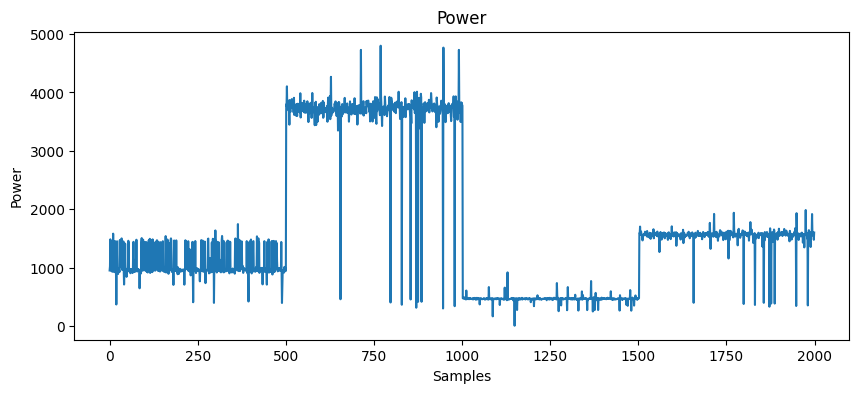

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df['Power'][:2000])
plt.title('Power')
plt.xlabel('Samples')
plt.ylabel('Power')
plt.show()

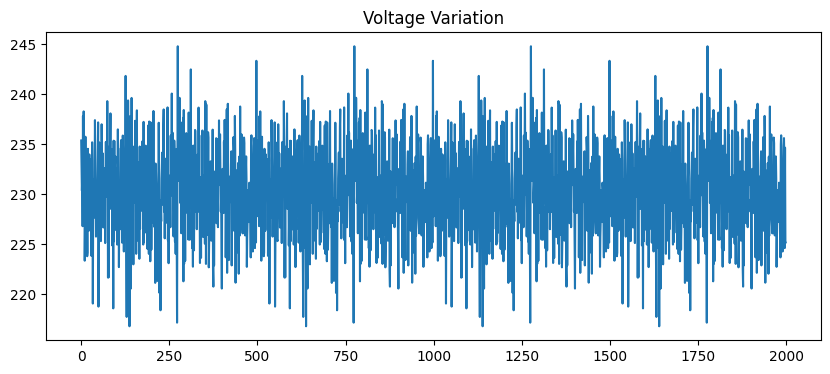

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df['Voltage'][:2000])
plt.title('Voltage Variation')
plt.show()

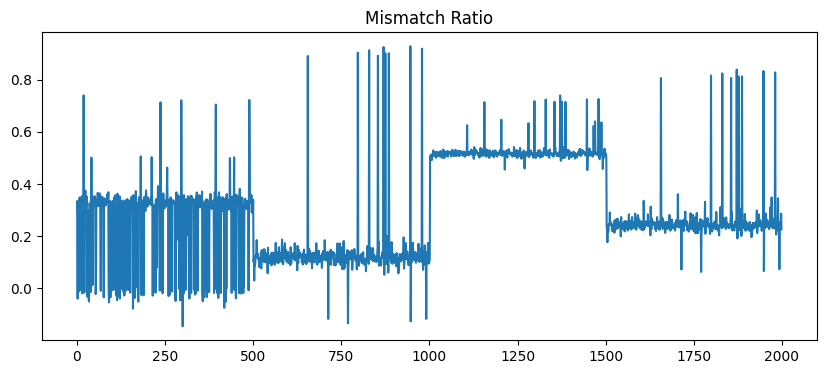

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df['Mismatch_Ratio'][:2000])
plt.title('Mismatch Ratio')
plt.show()

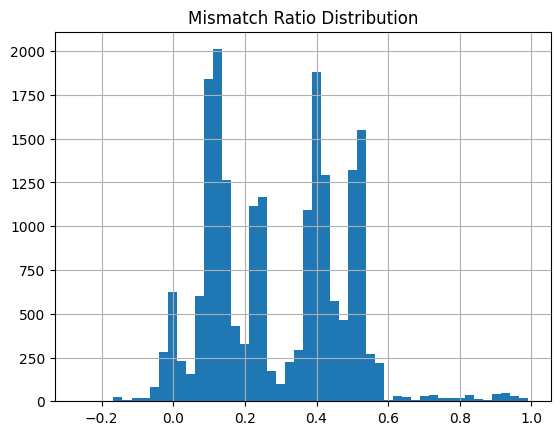

In [ ]:
plt.figure()
df['Mismatch_Ratio'].hist(bins=50)
plt.title('Mismatch Ratio Distribution')
plt.show()

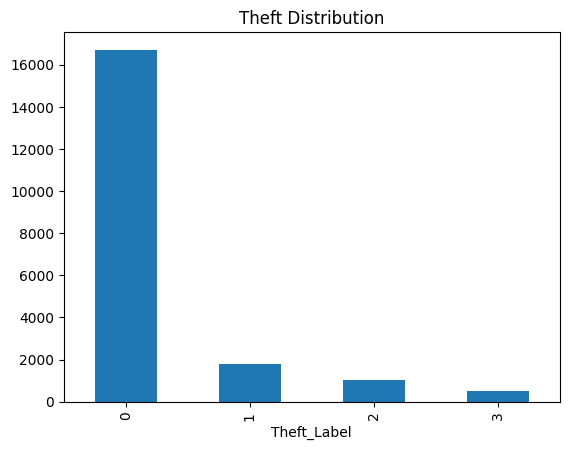

In [ ]:
df['Theft_Label'].value_counts().plot(kind='bar')
plt.title('Theft Distribution')
plt.show()

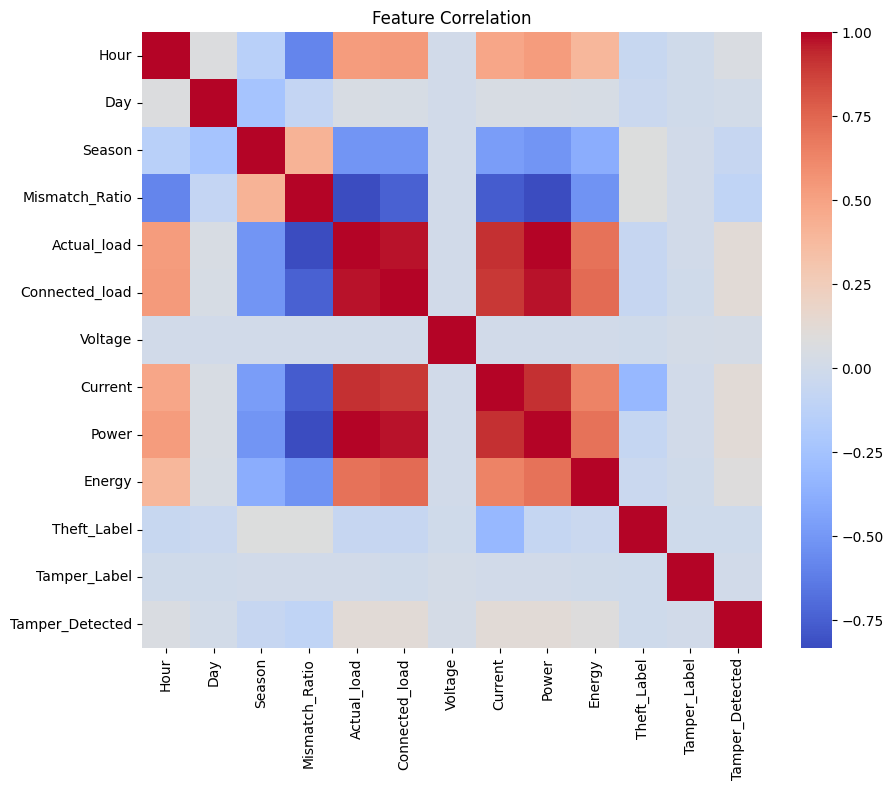

In [ ]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title('Feature Correlation')
plt.show()

In [ ]:
df = df.drop_duplicates()

##Feature Selection and Target Variables

The dataset is divided into:

### Input Features (X):
- Hour, Day, Season
- Mismatch Ratio
- Actual Load, Connected Load
- Voltage, Current, Power, Energy

### Target Variables (Y):
- Theft_Label
- Tamper_Label
- Tamper_Detected

This is a **multi-output classification problem**, where multiple labels are predicted simultaneously.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
X = df.drop(['Theft_Label', 'Tamper_Label', 'Tamper_Detected'], axis=1).values

Y1 = df['Theft_Label'].values
Y2 = df['Tamper_Label'].values
Y3 = df['Tamper_Detected'].values

##Random Forest Implementation (Custom)

A Random Forest classifier is implemented from scratch using:

### Key Components:
- **Gini Impurity**: Measures node purity
- **Best Split Selection**: Finds optimal feature and threshold
- **Decision Tree Construction**: Recursive tree building
- **Bootstrap Sampling**: Random sampling with replacement
- **Feature Subsampling**: Random subset of features at each split

### Improvements:
- Limited threshold values for faster computation
- Reduced tree depth to prevent overfitting
- Ensemble voting for final prediction

This approach avoids built-in libraries and demonstrates core ML understanding.

In [ ]:
indices = np.arange(len(X))
np.random.shuffle(indices)

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

Y1_train = Y1[train_idx]
Y1_test = Y1[test_idx]

Y2_train = Y2[train_idx]
Y2_test = Y2[test_idx]

Y3_train = Y3[train_idx]
Y3_test = Y3[test_idx]

In [ ]:
def gini(y):
    counts = np.bincount(y)
    probs = counts / len(y)
    return 1 - np.sum(probs**2)

In [ ]:
def best_split(X, y):
    best_feature = None
    best_threshold = None
    best_gain = 0

    parent_gini = gini(y)

    num_features = int(np.sqrt(X.shape[1]))
    features = np.random.choice(X.shape[1], num_features, replace=False)

    for feature in features:
        values = X[:, feature]
        thresholds = np.linspace(values.min(), values.max(), 10)

        for t in thresholds:
            left_idx = values <= t
            right_idx = values > t

            if np.sum(left_idx) == 0 or np.sum(right_idx) == 0:
                continue

            g_left = gini(y[left_idx])
            g_right = gini(y[right_idx])

            w_left = np.sum(left_idx) / len(y)
            w_right = np.sum(right_idx) / len(y)

            gain = parent_gini - (w_left * g_left + w_right * g_right)

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = t

    return best_feature, best_threshold

In [ ]:
def build_tree(X, y, depth=0, max_depth=3):
    if len(np.unique(y)) == 1 or depth == max_depth:
        return np.bincount(y).argmax()

    feature, threshold = best_split(X, y)

    if feature is None:
        return np.bincount(y).argmax()

    left_idx = X[:, feature] <= threshold
    right_idx = X[:, feature] > threshold

    left_tree = build_tree(X[left_idx], y[left_idx], depth+1, max_depth)
    right_tree = build_tree(X[right_idx], y[right_idx], depth+1, max_depth)

    return (feature, threshold, left_tree, right_tree)

In [ ]:
def predict_tree(tree, x):
    while isinstance(tree, tuple):
        feature, threshold, left, right = tree
        if x[feature] <= threshold:
            tree = left
        else:
            tree = right
    return tree

In [ ]:
def train_forest(X, y, n_trees=5):
    forest = []

    for _ in range(n_trees):
        idx = np.random.choice(len(X), len(X), replace=True)
        X_sample = X[idx]
        y_sample = y[idx]

        tree = build_tree(X_sample, y_sample)
        forest.append(tree)

    return forest

In [ ]:
def predict_forest(forest, X):
    preds = []

    for x in X:
        votes = []
        for tree in forest:
            votes.append(predict_tree(tree, x))

        preds.append(max(set(votes), key=votes.count))

    return np.array(preds)

##Model Training and Prediction

Three separate Random Forest models are trained for:
- Theft detection
- Tamper detection
- Tamper confirmation

Predictions are made using majority voting across trees.

This ensures robustness and reduces variance compared to a single decision tree.

In [ ]:
forest1 = train_forest(X_train, Y1_train)
forest2 = train_forest(X_train, Y2_train)
forest3 = train_forest(X_train, Y3_train)

In [ ]:
pred1 = predict_forest(forest1, X_test)
pred2 = predict_forest(forest2, X_test)
pred3 = predict_forest(forest3, X_test)

In [ ]:
print("Theft_Label Accuracy:", np.mean(pred1 == Y1_test))
print("Tamper_Label Accuracy:", np.mean(pred2 == Y2_test))
print("Tamper_Detected Accuracy:", np.mean(pred3 == Y3_test))

Theft_Label Accuracy: 0.9009481037924152
Tamper_Label Accuracy: 0.9550898203592815
Tamper_Detected Accuracy: 0.9735528942115769


## Isolation Forest for Anomaly Detection

An Isolation Forest is implemented from scratch to detect anomalies.

### Key Idea:
Anomalies are easier to isolate and require fewer splits.

### Steps:
- Random feature selection
- Random split generation
- Path length calculation
- Anomaly score computation

Data points with high anomaly scores are classified as suspicious.

This helps detect unknown or unseen fraud patterns.

In [ ]:
def build_iTree(X, depth, max_depth):
    if depth >= max_depth or len(X) <= 1:
        return depth

    feature = random.randint(0, X.shape[1] - 1)

    min_val = X[:, feature].min()
    max_val = X[:, feature].max()

    if min_val == max_val:
        return depth

    split = random.uniform(min_val, max_val)

    left = X[X[:, feature] < split]
    right = X[X[:, feature] >= split]

    return (feature, split,
            build_iTree(left, depth+1, max_depth),
            build_iTree(right, depth+1, max_depth))

In [ ]:
def path_length(tree, x, depth=0):
    while isinstance(tree, tuple):
        feature, split, left, right = tree
        if x[feature] < split:
            tree = left
        else:
            tree = right
        depth += 1
    return depth

In [ ]:
def train_iForest(X, n_trees=25, max_depth=8):
    forest = []

    for _ in range(n_trees):
        idx = np.random.choice(len(X), 256, replace=True)
        sample = X[idx]

        tree = build_iTree(sample, 0, max_depth)
        forest.append(tree)

    return forest

In [ ]:
def anomaly_score(forest, X):
    scores = []

    for x in X:
        path_lengths = []

        for tree in forest:
            path_lengths.append(path_length(tree, x))

        avg_path = np.mean(path_lengths)

        score = 2 ** (-avg_path)
        scores.append(score)

    return np.array(scores)

In [ ]:
import random
iForest = train_iForest(X_train)

scores = anomaly_score(iForest, X_test)

threshold = np.percentile(scores, 90)

anomalies = scores > threshold

print("Anomalies Detected:", np.sum(anomalies))

Anomalies Detected: 398


In [ ]:
anomaly_indices = np.where(anomalies == True)[0]

print("Theft cases inside anomalies:",
      np.sum(Y1_test[anomaly_indices]))

print("Tamper cases inside anomalies:",
      np.sum(Y2_test[anomaly_indices]))

Theft cases inside anomalies: 139
Tamper cases inside anomalies: 13


##Result Visualization

Multiple plots are used to interpret model performance:

### Graphs:
- Accuracy comparison bar chart
- Prediction vs actual plot
- Anomaly score distribution
- Threshold visualization
- Confusion matrix heatmap
- Feature importance chart
- Pie charts for anomaly distribution

These visualizations provide intuitive understanding of system performance.

In [ ]:
overall_acc = (
    np.mean(pred1 == Y1_test) +
    np.mean(pred2 == Y2_test) +
    np.mean(pred3 == Y3_test)
) / 3

print("Overall System Accuracy:", overall_acc)

Overall System Accuracy: 0.9431969394544245


In [ ]:
anomaly_indices = np.where(anomalies == True)[0]

theft_in_anomaly = np.sum(Y1_test[anomaly_indices])
tamper_in_anomaly = np.sum(Y2_test[anomaly_indices])

print("\n===== ANOMALY ANALYSIS =====")
print("Total Anomalies:", np.sum(anomalies))
print("Theft cases inside anomalies:", theft_in_anomaly)
print("Tamper cases inside anomalies:", tamper_in_anomaly)

precision = theft_in_anomaly / np.sum(anomalies)
print("Anomaly Precision (Theft):", precision)


===== ANOMALY ANALYSIS =====
Total Anomalies: 398
Theft cases inside anomalies: 139
Tamper cases inside anomalies: 13
Anomaly Precision (Theft): 0.3492462311557789


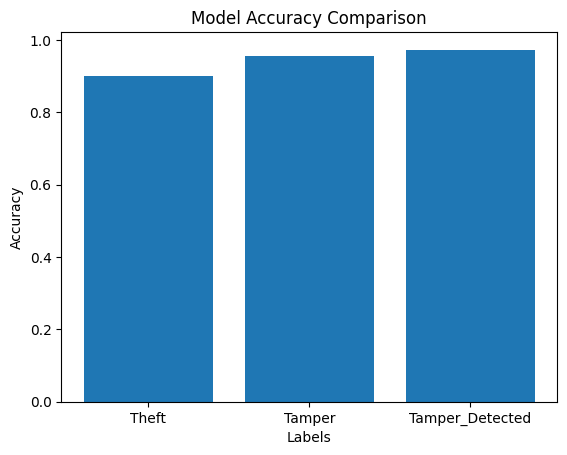

In [ ]:
import matplotlib.pyplot as plt

labels = ['Theft', 'Tamper', 'Tamper_Detected']
values = [acc1, acc2, acc3]

plt.figure()
plt.bar(labels, values)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Labels")
plt.show()

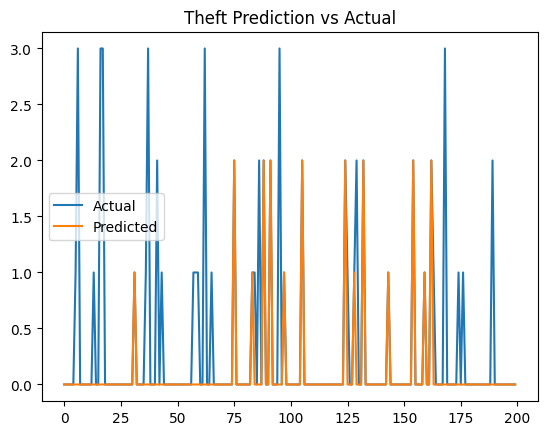

In [ ]:
plt.figure()
plt.plot(Y1_test[:200], label='Actual')
plt.plot(pred1[:200], label='Predicted')
plt.title("Theft Prediction vs Actual")
plt.legend()
plt.show()

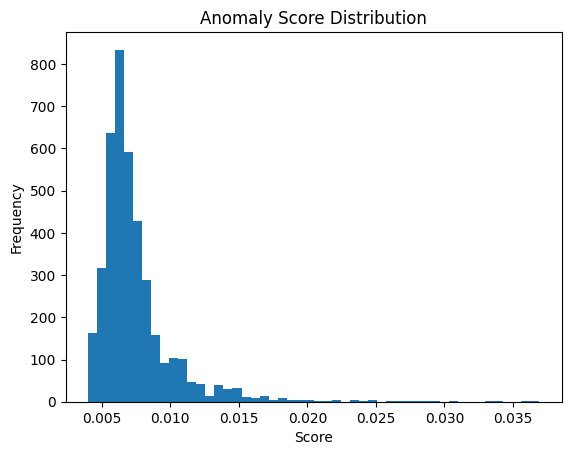

In [ ]:
plt.figure()
plt.hist(scores, bins=50)
plt.title("Anomaly Score Distribution")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

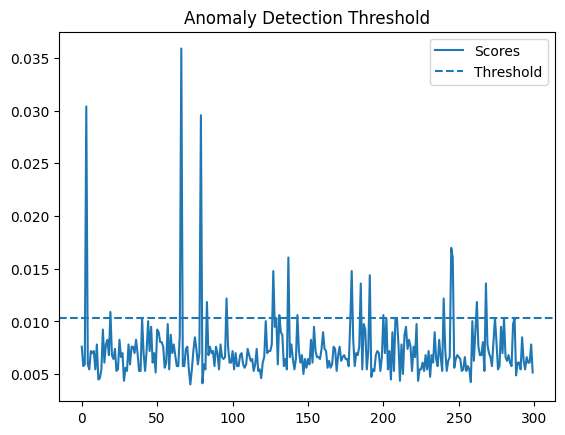

In [ ]:
plt.figure()
plt.plot(scores[:300], label="Scores")
plt.axhline(y=threshold, linestyle='--', label="Threshold")
plt.title("Anomaly Detection Threshold")
plt.legend()
plt.show()

In [ ]:
tp = np.sum((pred1 == 1) & (Y1_test == 1))
tn = np.sum((pred1 == 0) & (Y1_test == 0))
fp = np.sum((pred1 == 1) & (Y1_test == 0))
fn = np.sum((pred1 == 0) & (Y1_test == 1))

print("\n===== THEFT CONFUSION METRICS =====")
print("TP:", tp)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)


===== THEFT CONFUSION METRICS =====
TP: 92
TN: 3337
FP: 0
FN: 260


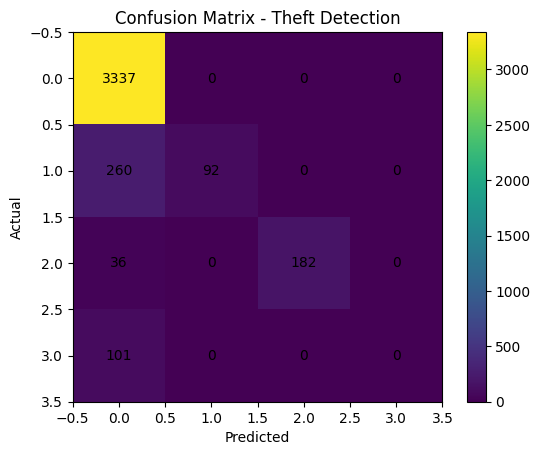

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(Y1_test, pred1)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix - Theft Detection")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

##Feature Importance Analysis

Feature importance is derived by counting how frequently each feature is used in decision tree splits.

### Key Findings:
- Mismatch Ratio is the most significant indicator
- Load-related features strongly influence predictions
- Electrical parameters like voltage and current also contribute

This validates the engineering relevance of selected features.

In [ ]:
feature_counts = np.zeros(X.shape[1])

def count_features(tree):
    if not isinstance(tree, tuple):
        return

    feature, threshold, left, right = tree
    feature_counts[feature] += 1

    count_features(left)
    count_features(right)

for tree in forest1:   # using Theft model
    count_features(tree)

In [ ]:
feature_importance = feature_counts / np.sum(feature_counts)

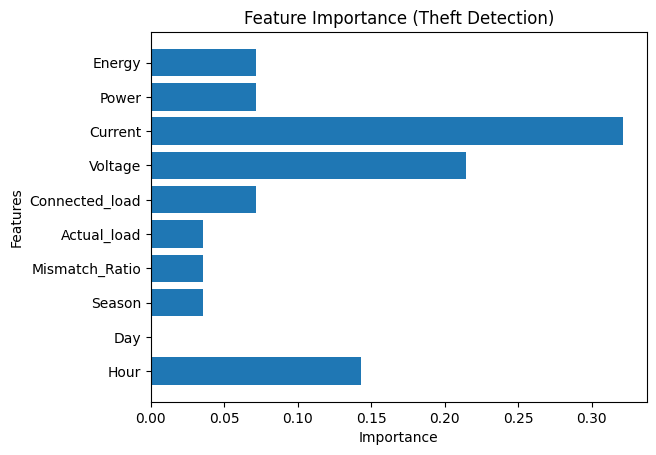

In [ ]:
feature_names = df.drop(['Theft_Label','Tamper_Label','Tamper_Detected'], axis=1).columns

plt.figure()
plt.barh(feature_names, feature_importance)
plt.title("Feature Importance (Theft Detection)")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

##Anomaly Distribution Analysis

Pie charts are used to visualize:

### 1. Anomaly vs Normal Distribution
Shows proportion of unusual consumption patterns.

### 2. Breakdown of Anomalies
- Theft cases
- Tamper cases
- Other anomalies

This provides a clear understanding of detection effectiveness.

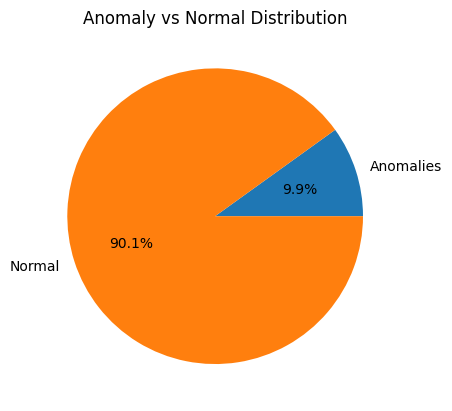

In [ ]:
total = len(anomalies)
anomaly_count = np.sum(anomalies)
normal_count = total - anomaly_count

labels = ['Anomalies', 'Normal']
sizes = [anomaly_count, normal_count]

plt.figure()
plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title("Anomaly vs Normal Distribution")
plt.show()

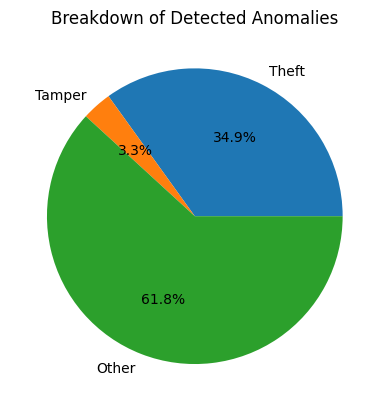

In [ ]:
theft = theft_in_anomaly
tamper = tamper_in_anomaly
others = anomaly_count - (theft + tamper)

labels = ['Theft', 'Tamper', 'Other']
sizes = [theft, tamper, others]

plt.figure()
plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title("Breakdown of Detected Anomalies")
plt.show()

##Conclusion

The project successfully demonstrates electricity theft detection using smart meter data.

### Key Outcomes:
- Random Forest provides accurate classification of theft and tampering
- Isolation Forest detects anomalous consumption patterns
- Hybrid approach improves overall system reliability

### Limitations:
- Presence of false positives in anomaly detection
- Synthetic dataset may not fully reflect real-world complexity

### Future Scope:
- Integration with real-time smart meter systems
- Deployment on embedded platforms (ESP32)
- Use of advanced ML models for improved accuracy